# 03 · Exploratory analysis · Part A: patterns over time

**Data:** Berka dataset (Czech bank, 1993-1998). All amounts are in **Czech koruna (CZK)**, not CAD.
**Source:** the clean files from notebook 02 (`data/processed/`). No raw values were changed.

**Rules for this notebook**
- Charts show **descriptive patterns**. A pattern is not a cause: the data has no information about *why* customers act as they do.
- "Customer-initiated" means every category except the three bank-generated ones (interest credited, penalty interest, service fees).
- Counts and values are different things: a posting-count pattern says nothing about money unless the value chart agrees.
- Overdraft events are a **proxy** (postings that take an account from non-negative to negative). There is no failed-transaction status.

Charts are saved to `reports/figures/` (aggregated numbers only, no customer rows).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

NAVY, TEAL, GREY, LIGHT = "#1B365D", "#1F8A8A", "#8C99A6", "#D9DEE3"
YEAR_COLORS = ["#B8C2CC", "#8C99A6", "#5B7C99", "#2F5D8A", "#1B365D", "#1F8A8A"]
plt.rcParams.update({
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": GREY,
    "axes.grid": True, "grid.color": LIGHT, "grid.linewidth": 0.8, "axes.axisbelow": True,
})
thousands = FuncFormatter(lambda v, _: f"{v:,.0f}")


def find_project_root(start: Path) -> Path:
    for folder in [start, *start.parents]:
        if (folder / "data" / "processed").exists():
            return folder
    raise FileNotFoundError("Could not find data/processed. Run notebook 02 first.")


ROOT = find_project_root(Path.cwd())
PROCESSED, REPORTS = ROOT / "data" / "processed", ROOT / "reports"
FIG_DIR = REPORTS / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"saved reports/figures/{name}.png")


BANK_GENERATED = ["Interest credited", "Penalty interest", "Service fees"]
print("Project root:", ROOT)

Project root: c:\Users\acer\Documents\banking-transaction-analytics


## 1. Load the clean data and check it

In [2]:
trans = pd.read_csv(
    PROCESSED / "trans_clean.csv",
    usecols=["trans_id", "account_id", "date", "year", "month", "year_month", "direction", "amount",
             "signed_amount", "balance", "balance_before", "transaction_category"],
    parse_dates=["date"],
    low_memory=False,
)
account = pd.read_csv(PROCESSED / "account_clean.csv", usecols=["account_id", "opened_date"], parse_dates=["opened_date"])
trans["origin"] = np.where(trans["transaction_category"].isin(BANK_GENERATED), "Bank-generated", "Customer-initiated")

FULL = len(trans) == 1_056_320
print(f"{len(trans):,} postings, {trans['account_id'].nunique():,} accounts, {trans['date'].min().date()} to {trans['date'].max().date()}")

assert trans["trans_id"].is_unique, "trans_id must be unique"
assert trans["year_month"].nunique() == 72, "expected 72 months (1993-01 to 1998-12)"
assert trans["amount"].min() >= 0, "amounts must not be negative"
if FULL:
    counts = trans["origin"].value_counts()
    assert counts["Bank-generated"] == 340_523 and counts["Customer-initiated"] == 715_797, "origin split differs from the SQL result"
    assert trans["amount"].sum() == 6_257_862_197, "total value differs from the SQL result"
    assert trans["signed_amount"].sum() == 197_103_131, "net flow differs from the SQL result"
    print("Matches the validated SQL totals: 340,523 bank-generated, 715,797 customer-initiated, value 6,257,862,197 CZK, net flow 197,103,131 CZK.")
else:
    print("Not the full dataset: the fixed-total checks are skipped.")

1,056,320 postings, 4,500 accounts, 1993-01-01 to 1998-12-31
Matches the validated SQL totals: 340,523 bank-generated, 715,797 customer-initiated, value 6,257,862,197 CZK, net flow 197,103,131 CZK.


## 2. Monthly table
One row per month. `open_accounts` is the number of accounts opened up to the end of the month. `postings_per_open_account` removes the effect of a growing account base (accounts were opened from 1993 to 1997 and none after 1997-12-29).

In [3]:
periods = pd.period_range("1993-01", "1998-12", freq="M").astype(str)
customer = trans[trans["origin"] == "Customer-initiated"]

monthly = pd.DataFrame(index=periods)
monthly["postings_all"] = trans.groupby("year_month").size()
monthly["postings_customer"] = customer.groupby("year_month").size()
monthly["value_all"] = trans.groupby("year_month")["amount"].sum()
monthly["net_flow"] = trans.groupby("year_month")["signed_amount"].sum()
monthly["overdraft_events"] = ((trans["balance_before"] >= 0) & (trans["balance"] < 0)).groupby(trans["year_month"]).sum()
monthly = monthly.fillna(0)
monthly["postings_bank"] = monthly["postings_all"] - monthly["postings_customer"]
monthly["open_accounts"] = account["opened_date"].dt.strftime("%Y-%m").value_counts().reindex(periods, fill_value=0).cumsum()
monthly["postings_per_open_account"] = monthly["postings_customer"] / monthly["open_accounts"].replace(0, np.nan)
monthly["year"] = [int(p[:4]) for p in periods]
monthly["month"] = [int(p[5:]) for p in periods]

display(monthly.drop(columns=["year", "month"]).head(3))
display(monthly.drop(columns=["year", "month"]).tail(3))

,postings_all,postings_customer,value_all,net_flow,overdraft_events,postings_bank,open_accounts,postings_per_open_account
1993-01,177,140,702159,632759,0,37,96,1.46
1993-02,395,290,2726934,2164080,0,105,194,1.49
1993-03,676,489,4730331,2980951,0,187,298,1.64


,postings_all,postings_customer,value_all,net_flow,overdraft_events,postings_bank,open_accounts,postings_per_open_account
1998-10,25689,16700,151891490,2150594,30,8989,4500,3.71
1998-11,25341,16352,148843990,2350274,37,8989,4500,3.63
1998-12,23553,19052,171697526,18615240,35,4501,4500,4.23


In [4]:
yearly = pd.DataFrame({
    "postings_all": monthly.groupby("year")["postings_all"].sum(),
    "postings_customer": monthly.groupby("year")["postings_customer"].sum(),
    "value_all_czk": monthly.groupby("year")["value_all"].sum(),
    "net_flow_czk": monthly.groupby("year")["net_flow"].sum(),
    "avg_open_accounts": monthly.groupby("year")["open_accounts"].mean(),
    "overdraft_events": monthly.groupby("year")["overdraft_events"].sum(),
})
yearly["customer_postings_per_avg_open_account"] = yearly["postings_customer"] / yearly["avg_open_accounts"]
yearly["overdraft_events_per_1000_postings"] = 1000 * yearly["overdraft_events"] / yearly["postings_all"]
yearly["overdraft_events_per_1000_open_accounts"] = 1000 * yearly["overdraft_events"] / yearly["avg_open_accounts"]
yearly

,postings_all,postings_customer,value_all_czk,net_flow_czk,avg_open_accounts,overdraft_events,customer_postings_per_avg_open_account,overdraft_events_per_1000_postings,overdraft_events_per_1000_open_accounts
year,,,,,,,,,
1993,28205,19209,204309987,36575247,614.08,10,31.28,0.35,16.28
1994,91628,61794,538796646,18275780,"1,372.25",64,45.03,0.70,46.64
1995,133022,90155,767739197,24397941,"1,927.33",87,46.78,0.65,45.14
1996,196779,133052,1163864249,49681611,"2,962.75",99,44.91,0.50,33.41
1997,284409,192063,1688347890,41042134,"4,091.50",216,46.94,0.76,52.79
1998,322277,219524,1894804228,27130418,"4,500.00",393,48.78,1.22,87.33


### Cross-check against the validated SQL results
The monthly numbers above come from pandas. The SQL validator saved MySQL's monthly numbers; they must be identical.

In [5]:
sql_report = REPORTS / "sql_validation_03_monthly_trends.csv"
if sql_report.exists():
    report = pd.read_csv(sql_report)

    def sql_series(name):
        rows = report[report["metric"].str.startswith(name + "|")]
        return pd.Series(rows["mysql"].to_numpy(), index=rows["metric"].str.split("|").str[1].to_numpy())

    pairs = {
        "monthly_postings": "postings_all", "monthly_value": "value_all", "monthly_net_flow": "net_flow",
        "monthly_overdraft_triggers": "overdraft_events", "open_accounts": "open_accounts",
    }
    for sql_name, column in pairs.items():
        sql_values = sql_series(sql_name).reindex(periods)
        assert np.allclose(sql_values.astype(float), monthly[column].astype(float)), f"{column} differs from SQL ({sql_name})"
    print(f"pandas matches the validated SQL results for {len(pairs)} monthly measures x {len(periods)} months.")
else:
    print("reports/sql_validation_03_monthly_trends.csv not found: run the SQL validator for file 03 to enable this cross-check.")

pandas matches the validated SQL results for 5 monthly measures x 72 months.


## 3. Chart 1: how much of the activity does the bank generate itself?
**What to look at:** the height of the grey part relative to the teal part over time. This is a count of postings, not money.

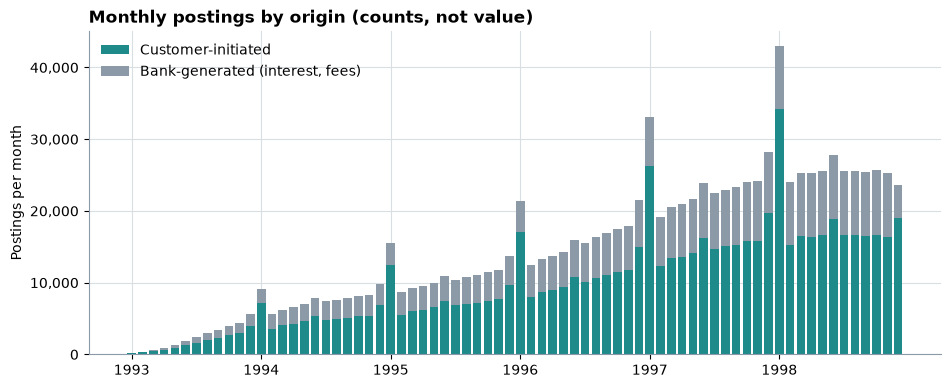

saved reports/figures/01_monthly_postings_by_origin.png


In [6]:
x = np.arange(len(periods))
jan_ticks = [i for i, p in enumerate(periods) if p.endswith("-01")]
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(x, monthly["postings_customer"], color=TEAL, label="Customer-initiated")
ax.bar(x, monthly["postings_bank"], bottom=monthly["postings_customer"], color=GREY, label="Bank-generated (interest, fees)")
ax.set_xticks(jan_ticks)
ax.set_xticklabels([periods[i][:4] for i in jan_ticks])
ax.yaxis.set_major_formatter(thousands)
ax.set_ylabel("Postings per month")
ax.set_title("Monthly postings by origin (counts, not value)")
ax.legend(frameon=False, loc="upper left")
save(fig, "01_monthly_postings_by_origin")

## 4. Chart 2: monthly net flow
Net flow is credits minus debits for all postings, in millions of CZK. Teal bars are positive months, navy bars negative months.

**What to look at:** which months are negative, and whether the same calendar months are negative in several years.

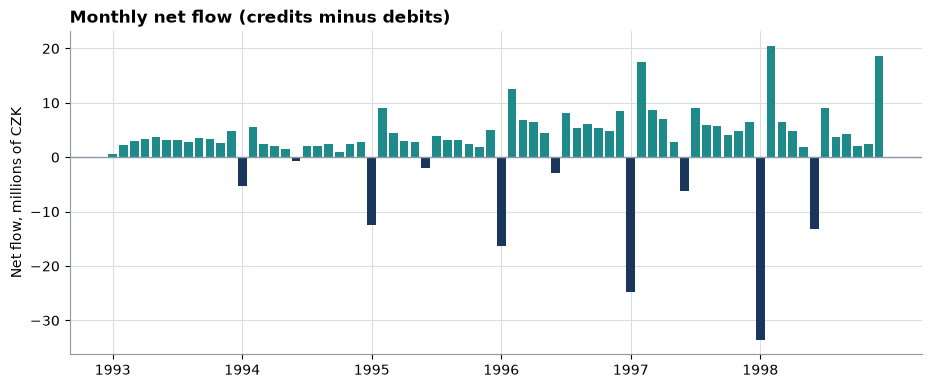

saved reports/figures/02_monthly_net_flow.png
Months with a negative net flow, by calendar month:


month,1,6
number_of_years,5,5


In [7]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.bar(x, monthly["net_flow"] / 1e6, color=[TEAL if v >= 0 else NAVY for v in monthly["net_flow"]])
ax.axhline(0, color=GREY, linewidth=1)
ax.set_xticks(jan_ticks)
ax.set_xticklabels([periods[i][:4] for i in jan_ticks])
ax.set_ylabel("Net flow, millions of CZK")
ax.set_title("Monthly net flow (credits minus debits)")
save(fig, "02_monthly_net_flow")

negative = monthly[monthly["net_flow"] < 0]
print("Months with a negative net flow, by calendar month:")
display(negative.groupby("month").size().rename("number_of_years").to_frame().T)

## 5. Chart 3: activity per open account
This chart divides customer-initiated postings by the number of open accounts, so a growing account base does not look like growing activity. The first months are noisy because very few accounts existed.

**What to look at:** whether the line still rises after 1997, when the account base stopped growing.

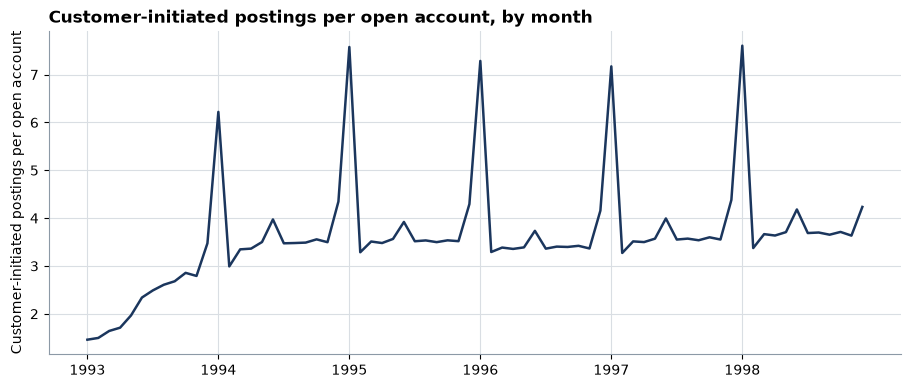

saved reports/figures/03_postings_per_open_account.png


In [8]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(x, monthly["postings_per_open_account"], color=NAVY, linewidth=1.8)
ax.set_xticks(jan_ticks)
ax.set_xticklabels([periods[i][:4] for i in jan_ticks])
ax.set_ylabel("Customer-initiated postings per open account")
ax.set_title("Customer-initiated postings per open account, by month")
save(fig, "03_postings_per_open_account")

## 6. Chart 4: calendar pattern by year
Each cell is a month's customer-initiated postings per open account, divided by the **average month of the same year**. 1.00 is an average month of that year; 1.50 is 50% above it. Dividing within a year removes the growth between years.

**What to look at:** whether the same calendar columns are darker in every row.

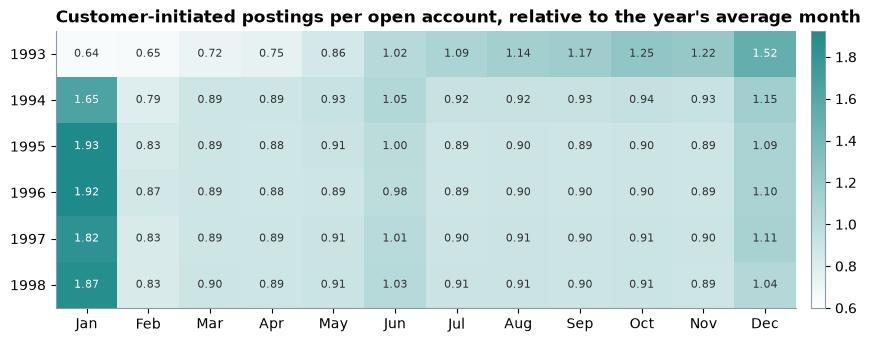

saved reports/figures/04_calendar_pattern_by_year.png


In [9]:
heat = monthly.pivot(index="year", columns="month", values="postings_per_open_account")
index_table = heat.div(heat.mean(axis=1), axis=0)

cmap = LinearSegmentedColormap.from_list("white_teal", ["#FFFFFF", TEAL])
fig, ax = plt.subplots(figsize=(10, 3.6))
image = ax.imshow(index_table.values, cmap=cmap, aspect="auto", vmin=0.6, vmax=max(1.6, np.nanmax(index_table.values)))
ax.set_xticks(range(12))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_yticks(range(len(index_table)))
ax.set_yticklabels(index_table.index)
ax.grid(False)
for r in range(index_table.shape[0]):
    for c in range(index_table.shape[1]):
        value = index_table.values[r, c]
        if not np.isnan(value):
            ax.text(c, r, f"{value:.2f}", ha="center", va="center", fontsize=8, color="white" if value > 1.35 else "#333333")
ax.set_title("Customer-initiated postings per open account, relative to the year's average month")
fig.colorbar(image, ax=ax, fraction=0.025, pad=0.02)
save(fig, "04_calendar_pattern_by_year")

## 7. Chart 5: cash and card withdrawals by calendar month
Posting counts per 1,000 open accounts, one line per year. These are **counts**, not money: a month can have many small withdrawals or few large ones.

**What to look at:** whether each year's line peaks in the same months, and whether the lines sit higher in later years.

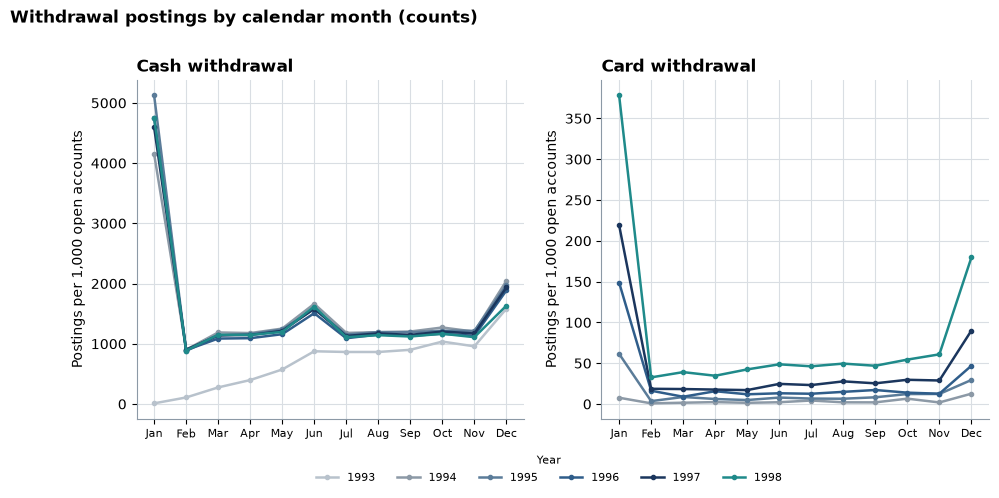

saved reports/figures/05_withdrawals_by_calendar_month.png


In [10]:
from matplotlib.lines import Line2D

wd = trans[trans["transaction_category"].isin(["Cash withdrawal", "Card withdrawal"])]
wd_counts = wd.groupby(["transaction_category", "year", "month"]).size().rename("postings").reset_index()
wd_counts["period"] = wd_counts["year"].astype(str) + "-" + wd_counts["month"].astype(str).str.zfill(2)
wd_counts["open_accounts"] = wd_counts["period"].map(monthly["open_accounts"])
wd_counts["per_1000_open_accounts"] = 1000 * wd_counts["postings"] / wd_counts["open_accounts"].replace(0, np.nan)

YEAR_COLOR = dict(zip(range(1993, 1999), YEAR_COLORS))  # one colour per year, identical in both panels
month_names = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4), sharex=True)
for ax, category in zip(axes, ["Cash withdrawal", "Card withdrawal"]):
    subset = wd_counts[wd_counts["transaction_category"] == category]
    for year, group in subset.groupby("year"):
        ax.plot(group["month"], group["per_1000_open_accounts"], color=YEAR_COLOR[year], linewidth=1.8, marker="o", markersize=3)
    ax.set_title(category)
    ax.set_xticks(range(1, 13))
    ax.set_xticklabels(month_names, fontsize=8)
    ax.set_ylabel("Postings per 1,000 open accounts")
handles = [Line2D([0], [0], color=color, linewidth=1.8, marker="o", markersize=3, label=str(year)) for year, color in YEAR_COLOR.items()]
fig.legend(handles=handles, loc="lower center", ncol=6, frameon=False, title="Year", title_fontsize=8, fontsize=8, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Withdrawal postings by calendar month (counts)", x=0.01, y=1.04, ha="left", fontweight="bold")
save(fig, "05_withdrawals_by_calendar_month")

## 8. Chart 6: overdraft events per 1,000 postings
An overdraft event is a posting that takes an account from a non-negative balance to a negative one. It is a **proxy for risk, not a failed transaction**. Rates are per 1,000 postings of all kinds.

**What to look at:** the direction of the bars and the counts written above them. 1998 has a fixed account base.

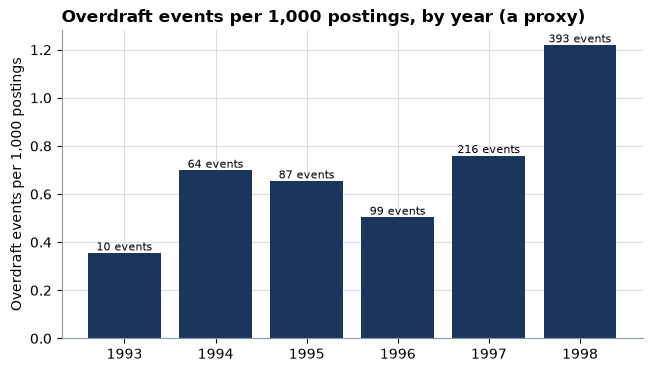

saved reports/figures/06_overdraft_events_by_year.png


In [11]:
fig, ax = plt.subplots(figsize=(7.5, 4))
bars = ax.bar(yearly.index.astype(str), yearly["overdraft_events_per_1000_postings"], color=NAVY)
for bar, events in zip(bars, yearly["overdraft_events"]):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"{int(events):,} events", ha="center", va="bottom", fontsize=8)
ax.set_ylabel("Overdraft events per 1,000 postings")
ax.set_title("Overdraft events per 1,000 postings, by year (a proxy)")
save(fig, "06_overdraft_events_by_year")

## 9. Chart 7: what makes up the January, June and December net flows?
Net flow is credits minus debits. This splits each month's net flow by category for **1998** (the one year with a fixed account base) and compares January, June and December with the average of the other nine months. Bars to the left are net outflows.

**What to look at:** which categories are far from their "average other month" bar in January and June. This shows **what** differs, not **why**. The tables below show the same split for January and June in every year from 1994 to 1998.

1998, net flow by category, millions of CZK:


,January,June,December,average other month
transaction_category,,,,
Cash withdrawal,-90.99,-91.26,-55.06,-50.40
Household payment,-13.05,-14.11,-13.99,-13.84
Card withdrawal,-3.56,-0.54,-1.85,-0.49
Outgoing transfer,-2.99,-3.18,-3.19,-3.15
Loan payment,-1.53,-1.76,-1.78,-1.71
Insurance payment,-0.62,-0.66,-0.67,-0.66
Service fees,-0.07,-0.08,0.00,-0.08
Penalty interest,-0.00,-0.00,-0.00,-0.00
Interest credited,0.65,0.73,0.80,0.72


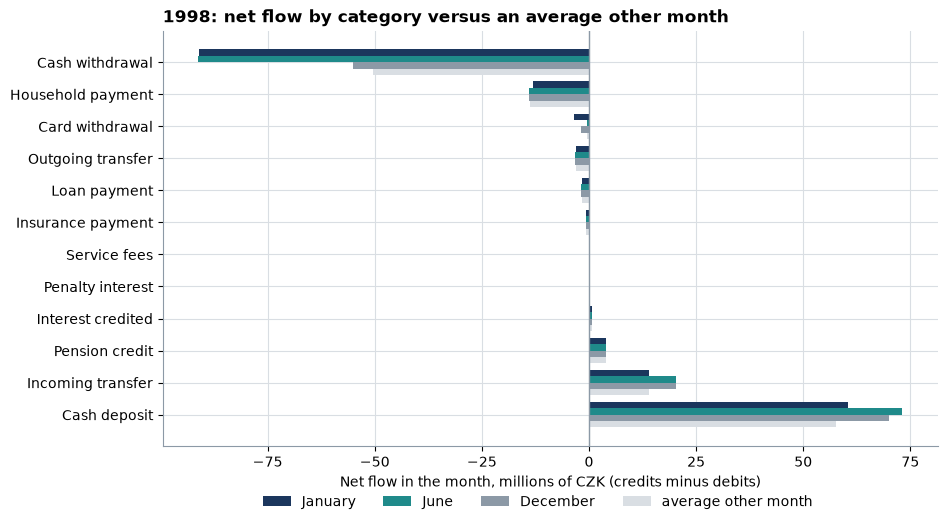

saved reports/figures/07_net_flow_by_category_1998.png
January: net flow by category and year, millions of CZK:


,1994,1995,1996,1997,1998
transaction_category,,,,,
Card withdrawal,-0.02,-0.21,-0.70,-1.70,-3.56
Cash deposit,13.81,20.12,29.40,47.24,60.49
Cash withdrawal,-20.90,-33.14,-45.71,-72.03,-90.99
Household payment,-2.30,-4.21,-6.07,-9.57,-13.05
Incoming transfer,3.55,5.00,6.87,11.20,14.04
Insurance payment,-0.12,-0.23,-0.32,-0.44,-0.62
Interest credited,0.14,0.21,0.31,0.49,0.65
Loan payment,-0.09,-0.48,-0.67,-0.99,-1.53
Outgoing transfer,-0.53,-1.06,-1.43,-2.27,-2.99


June: net flow by category and year, millions of CZK:


,1994,1995,1996,1997,1998
transaction_category,,,,,
Card withdrawal,-0.01,-0.04,-0.09,-0.25,-0.54
Cash deposit,22.09,28.97,42.41,64.90,73.16
Cash withdrawal,-25.45,-34.85,-50.82,-77.55,-91.26
Household payment,-3.42,-4.86,-7.11,-11.17,-14.11
Incoming transfer,5.97,8.82,12.56,18.00,20.34
Insurance payment,-0.18,-0.24,-0.33,-0.52,-0.66
Interest credited,0.19,0.27,0.41,0.61,0.73
Loan payment,-0.24,-0.58,-0.76,-1.21,-1.76
Outgoing transfer,-0.84,-1.20,-1.69,-2.65,-3.18


In [12]:
net_by_category = trans.groupby(["year", "month", "transaction_category"])["signed_amount"].sum().unstack("transaction_category", fill_value=0)
assert np.allclose(net_by_category.sum(axis=1).to_numpy(), monthly["net_flow"].to_numpy()), "category net flows must add up to the monthly net flow"


def calendar_comparison(year):
    frame = net_by_category.loc[year]
    return pd.DataFrame({
        "January": frame.loc[1], "June": frame.loc[6], "December": frame.loc[12],
        "average other month": frame.drop(index=[1, 6, 12]).mean(),
    }) / 1e6


comparison = calendar_comparison(1998).sort_values("January")
print("1998, net flow by category, millions of CZK:")
display(comparison.round(2))

fig, ax = plt.subplots(figsize=(10, 5.4))
rows = np.arange(len(comparison))
bar_height = 0.2
for offset, (column, color) in enumerate([("January", NAVY), ("June", TEAL), ("December", GREY), ("average other month", LIGHT)]):
    ax.barh(rows + (offset - 1.5) * bar_height, comparison[column], height=bar_height, color=color, label=column)
ax.set_yticks(rows)
ax.set_yticklabels(comparison.index)
ax.invert_yaxis()
ax.axvline(0, color=GREY, linewidth=1)
ax.set_xlabel("Net flow in the month, millions of CZK (credits minus debits)")
ax.set_title("1998: net flow by category versus an average other month")
fig.legend(loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.03))
save(fig, "07_net_flow_by_category_1998")

for month, label in [(1, "January"), (6, "June")]:
    table = pd.DataFrame({year: net_by_category.loc[(year, month)] for year in range(1994, 1999)}) / 1e6
    print(f"{label}: net flow by category and year, millions of CZK:")
    display(table.round(2))

## 10. Your observations (write these in your own words before moving on)
Write what you **see**, then what you **do not know**. Suggested structure:

1. **Origin:** what share of postings is bank-generated, and what does the value chart or table say about money?
2. **Growth:** how much of the growth in postings disappears once you divide by open accounts? Which years are comparable?
3. **Calendar:** which calendar months stand out in Charts 2, 4 and 5? Do the same months stand out in every year, or only in some?
4. **Overdraft events:** what do the bars show, and what can they **not** tell you (no failed-transaction status, events are not accounts)?
5. **Unknowns:** list at least three questions the data cannot answer (for example why customers withdraw more in some months).

Careful wording: write "is consistent with" and "coincides with", not "because" or "caused by".
6. **Net flow by category:** which categories differ most from an average month in January and in June (Chart 7), and does the same pattern appear in every year (the two tables)?